# RQ3: how neighbor information enters the predictor

All RQ3 analysis in one place: statistics, figures, variability and a `for_chat/` export.
All ten systems (set `DROP = "A.UML"` for nine). Zero-shot UniXcoder is excluded as in the paper (`INCLUDE_ZS = False`).
Data are read-only from the supervisor's package; nothing in `new_paper/` is changed. ArgoUML 0.24 UniXcoder fits
(supervisor rerun, 8 Oct) are read from `results/RQ3_controls/ArgoUML_024/` because the package has none.

**Sections:** 1 Config and theme, 2 Data, 3 On/off statistics, 4 Rewiring control, 5 Figures,
6 Variability and where each predictor is better, 7 Counts quoted in the text, 8 Verification, 9 Export for the chat.

Run from the `HetMap` folder (the notebook's own folder).

## 1. Config and theme

In [26]:
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent       # HetMap
PKG = Path(r"C:\Users\JABEERAK\Architecture_Recovery\HetMap\new_paper\hetmap-rq3-experiment-data\rq3\review\data")
OUT = ROOT / "results" / "rq3_nine"
OUT.mkdir(parents=True, exist_ok=True)
ARGO = ROOT / "results" / "RQ3_controls" / "ArgoUML_024"      # ArgoUML 0.24 UniXcoder controls (320 fits)

SCHED = "self"            # schedule used by the predictor-comparison figures: "self" or "sup"
INCLUDE_ZS = False        # zero-shot UniXcoder is not part of the paper
DROP = None            # None = all ten systems; "A.UML" = nine
ALPHA = 0.05
print("HetMap root:", ROOT.resolve())
print("Outputs:", OUT.resolve())

HetMap root: C:\Users\JABEERAK\Architecture_Recovery\HetMap
Outputs: C:\Users\JABEERAK\Architecture_Recovery\HetMap\results\rq3_nine


In [27]:
import numpy as np
from matplotlib.ticker import MaxNLocator
import pandas as pd
from pathlib import Path
from scipy.stats import ranksums
import shutil, warnings
from scipy.stats import mannwhitneyu, wilcoxon, binomtest
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations

warnings.filterwarnings("ignore")
plt.rcParams["text.usetex"] = True
try:  # fall back to mathtext if no LaTeX installation is available
    _f = plt.figure(); _f.text(0.5, 0.5, r"$\langle k \rangle$"); _f.canvas.draw(); plt.close(_f)
except Exception as _e:
    print("LaTeX unavailable, using mathtext:", type(_e).__name__)
    plt.rcParams["text.usetex"] = False
sns.set_theme(
    style="ticks",
    rc={
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.spines.left": True,
        "axes.spines.bottom": True,
        "axes.edgecolor": "black",
        "axes.linewidth": 1,
        "xtick.bottom": True,
        "ytick.left": True,
        "xtick.major.size": 3,
        "ytick.major.size": 3,
        "xtick.major.width": 1,
        "ytick.major.width": 1,
        "axes.grid": True,
        "axes.grid.axis": "x",
        "grid.alpha": 0.7,
        "grid.linestyle": "-",
        "grid.linewidth": 0.7,
    }
)
plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "black",
    "axes.linewidth": 1,
    "xtick.major.size":4,
    "ytick.major.size": 4,
    "xtick.major.width": 1,
    "ytick.major.width": 1,
    "xtick.color": "black",
    "ytick.color": "black",
    "axes.axisbelow": True,
    "grid.alpha": 0.4,
    "grid.linestyle": "-",
    "grid.linewidth": 0.5,
})
ALPHA = 0.05

In [28]:
from matplotlib.colors import to_rgba
from matplotlib.patches import FancyBboxPatch
from matplotlib.lines import Line2D
from scipy.stats import wilcoxon

# ---- colours unchanged from the existing notebooks
METHODS = [("MLP0", "MLP", "#C9CED6"), ("MLPN", r"$\mathcal{N}_\mathrm{MLP}$", "#CAB2D6"), 
           ("GAT", "GAT", "#A6CEE3"), ("HGT", "HGT", "#B2DF8A"),
           ]
PASTEL = {m: c for m, _, c in METHODS}
ORDER = [m for m, _, _ in METHODS]
LABELS = [l for _, l, _ in METHODS]
EDGE = "#44546A"
SCHED_COLOR = {"sup": "#4c72b0", "self": "#c44e52"}
SCHED_LABEL = {"sup": "Supervised-only", "self": "Self-training"}

SYSTEMS = ["A.UML", "C.Img", "Jabref", "Lucene", "SH-3D", "TeamMates", "Bash", "HDF", "Chrome", "HDC"]
LAB = {"Jabref": "JabRef", "TeamMates": "T.Mates"}
MODELS = [("HGT", "HGT"), ("uHGT", "HGT-U"), ("GAT", "GAT"), ("MLP", r"$\mathcal{N}_\mathrm{MLP}$")]
REP_LABEL = {"W2V": "W2V", "N2V": "N2V", "UXC_FT": r"UXC$_{FT}$",  "UXC_ZS": r"UXC$_{ZS}$"}
REPS = ["W2V", "N2V", "UXC_FT",] + (["UXC_ZS"] if INCLUDE_ZS else [])
METRICS = [ ("f1_micro", "Micro-F1"),("f1_macro", "Macro-F1"),]


def bold(txt):
    # usetex ignores fontweight, so bold via LaTeX; plain text when mathtext is the fallback
    return rf"\textbf{{{txt}}}" if plt.rcParams["text.usetex"] else txt


def holm(p):
    p = np.asarray(p, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (len(p) - rank) * p[i])
        adj[i] = min(1.0, run)
    return adj


def pval(x):
    x = np.asarray(x, float)
    if np.allclose(x, 0):
        return 1.0
    return float(wilcoxon(x, zero_method="wilcox", method="auto").pvalue)


def save_fig(fig, name):
    fig.savefig(OUT / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight")

## 2. Data

One tidy table, `runs`: one row per fit (final scores). N2V has three embedding seeds and ten splits;
W2V and UniXcoder have one saved embedding (seed 0) and ten splits. `neighbors` is True when neighbor
information is on (HGT/GAT messages, or the neighbor block of the neighbor MLP).

In [29]:
def parse(df):
    c = df["condition"]
    df["model"] = np.select([c.str.startswith("hgt_directed_typed"), c.str.startswith("hgt_bidirectional_untyped"),
                             c.str.startswith("gat"), c.str.startswith("mlp")], ["HGT", "uHGT", "GAT", "MLP"], default="")
    df["schedule"] = np.where(c.str.contains("self190"), "self", "sup")
    df["neighbors"] = c.str.rsplit("_", n=1).str[-1].isin(["on", "undirected"])
    return df


KEEP = ["system", "rep", "model", "schedule", "neighbors", "seed", "split",
        "f1_macro", "f1_micro", "precision_macro", "recall_macro"]

full = pd.read_csv(PKG / "full/per-run.csv")
gat = pd.read_csv(PKG / "gat/outputs/analysis/per-run.csv")
n2v = pd.concat([full, gat])
n2v = parse(n2v[(n2v.stage == "final") & (n2v.system != DROP)].copy())
n2v["rep"], n2v["seed"], n2v["split"] = "N2V", n2v["feature_seed"], n2v["run_id"]

emb = pd.read_csv(PKG / "embedding-controls/outputs/analysis/per-run.csv")
argo = pd.read_csv(ARGO / "per-run.csv")                     # ArgoUML 0.24 UniXcoder (the package has none)
argo = argo[~argo.set_index(["system", "representation"]).index.isin(
    emb.set_index(["system", "representation"]).index.unique())]   # add only what the package lacks
emb = pd.concat([emb, argo], ignore_index=True)
emb = parse(emb[(emb.stage == "final") & (emb.system != DROP) & emb.representation.isin(REPS)].copy())
emb["rep"], emb["seed"], emb["split"] = emb["representation"], 0, emb["run_id"]

runs = pd.concat([n2v[KEEP], emb[KEEP]], ignore_index=True)
runs = runs[runs.model != ""]
runs.to_csv(OUT / "rq3_runs.csv", index=False)
print(runs.groupby(["rep", "model"]).size().unstack())
print("systems:", sorted(runs.system.unique()))
n_sys = runs.groupby("rep").system.nunique()
print(n_sys.to_dict())
assert (n_sys == len(SYSTEMS) - (DROP is not None)).all(), n_sys      # every vector covers every system

model    GAT   HGT   MLP  uHGT
rep                           
N2V     1200  1200  1200  1200
UXC_FT   400   400   400   400
W2V      400   400   400   400
systems: ['A.UML', 'Bash', 'C.Img', 'Chrome', 'HDC', 'HDF', 'Jabref', 'Lucene', 'SH-3D', 'TeamMates']
{'N2V': 10, 'UXC_FT': 10, 'W2V': 10}


## 3. On/off statistics

Paired difference per fit pair (neighbors on minus off; same system, seed, split). Per system: median over splits
for each embedding seed, then the median of the seed medians (N2V has three seeds, the others one), the seed range,
and whether the sign changes across seeds. Significance: exact Wilcoxon signed-rank on the ten split-level
differences (averaged over seeds), Holm across the systems for each model, schedule, vector and metric.
Ten splits only allow near-unanimous differences to survive correction, so the tests are exploratory.

In [30]:
def paired(runs):
    keys = ["system", "rep", "model", "schedule", "seed", "split"]
    w = runs.pivot_table(index=keys, columns="neighbors", values=["f1_macro", "f1_micro"])
    return pd.DataFrame({m: w[(m, True)] - w[(m, False)] for m in ["f1_macro", "f1_micro"]}).reset_index()


def system_table(d):
    rows = []
    for (sy, rep, m, s), g in d.groupby(["system", "rep", "model", "schedule"]):
        for metric in ["f1_macro", "f1_micro"]:
            seed_med = g.groupby("seed")[metric].median()
            avg = g.groupby("split")[metric].mean()
            rows.append(dict(system=sy, rep=rep, model=m, schedule=s, metric=metric.replace("f1_", ""),
                             median=float(seed_med.median()), smin=float(seed_med.min()), smax=float(seed_med.max()),
                             n_seeds=len(seed_med),
                             sign_change=bool(len(seed_med) > 1 and seed_med.min() < -1e-9 and seed_med.max() > 1e-9),
                             p=pval(avg.values), n_splits=len(avg)))
    t = pd.DataFrame(rows)
    t["p_holm"] = np.nan
    for _, idx in t.groupby(["rep", "model", "schedule", "metric"]).groups.items():
        t.loc[idx, "p_holm"] = holm(t.loc[idx, "p"].values)
    t["sig"] = t.p_holm < ALPHA
    return t


def summarise(t):
    rows = []
    for (rep, m, s, me), g in t.groupby(["rep", "model", "schedule", "metric"]):
        rows.append(dict(rep=rep, model=m, schedule=s, metric=me, n_sys=len(g), median=g["median"].median(),
                         pos=int((g["median"] > 1e-9).sum()), up=int((g.sig & (g["median"] > 0)).sum()),
                         down=int((g.sig & (g["median"] < 0)).sum())))
    return pd.DataFrame(rows)


d_onoff = paired(runs)
sys_tab = system_table(d_onoff)
reps_tab = summarise(sys_tab)
sys_tab[sys_tab.rep == "N2V"].to_csv(OUT / "rq3_n2v_system.csv", index=False)
sys_tab[sys_tab.rep != "N2V"].to_csv(OUT / "rq3_emb_system.csv", index=False)
reps_tab.to_csv(OUT / "rq3_reps.csv", index=False)
display(reps_tab[reps_tab.metric == "macro"].pivot_table(index=["model", "schedule"], columns="rep",
                                                          values="median").round(1))

rep             N2V  UXC_FT  W2V
model schedule                  
GAT   self      2.8     3.3  5.0
      sup       1.1     4.1  6.0
HGT   self     -5.4    -2.5 -4.4
      sup      -5.8    -3.6 -4.1
MLP   self      2.4     6.5  4.0
      sup       1.0     4.7  4.8
uHGT  self      0.3     2.0  2.0
      sup       0.4     0.9  2.8

## 4. Rewiring control (Lucene, JabRef, Bash)

With neighbors off, how far do real N2V vectors exceed vectors learned on a degree-preserving rewired graph and
real vectors shuffled among files; and what does HGT message passing change with each kind of vector.
Medians over all 30 runs (3 seeds x 10 splits).

In [31]:
enc = pd.read_csv(PKG / "encoding/per-run.csv")
pe = enc.pivot_table(index=["system", "feature_seed", "run_id"], columns="condition", values=["f1_macro", "f1_micro"])
rows = []
for sy in ["Lucene", "Jabref", "Bash"]:
    for metric in ["f1_macro", "f1_micro"]:
        w = pe[metric].xs(sy, level="system")
        rows.append(dict(system=sy, metric=metric.replace("f1_", ""),
                         real_minus_rewired=(w.real_off - w.rewired_off).median(),
                         real_minus_shuffled=(w.real_off - w.row_permuted_off).median(),
                         hgt_on_off_real=(w.real_on - w.real_off).median(),
                         hgt_on_off_rewired=(w.rewired_on - w.rewired_off).median(),
                         hgt_on_off_shuffled=(w.row_permuted_on - w.row_permuted_off).median()))
rewiring = pd.DataFrame(rows)
rewiring.to_csv(OUT / "rq3_rewiring.csv", index=False)
display(rewiring.round(1))

,system,metric,real_minus_rewired,real_minus_shuffled,hgt_on_off_real,hgt_on_off_rewired,hgt_on_off_shuffled
0,Lucene,macro,56.2,53.8,-8.2,8.2,6.5
1,Lucene,micro,57.0,57.6,-3.8,8.5,9.7
2,Jabref,macro,22.5,21.3,-2.4,8.9,9.5
3,Jabref,micro,27.0,30.1,-2.4,13.2,15.2
4,Bash,macro,33.9,34.1,-3.8,2.7,2.7
5,Bash,micro,34.6,39.3,1.2,5.4,6.3


## 5. Figures

### 5.1 Neighbor information on minus off, per system (N2V)

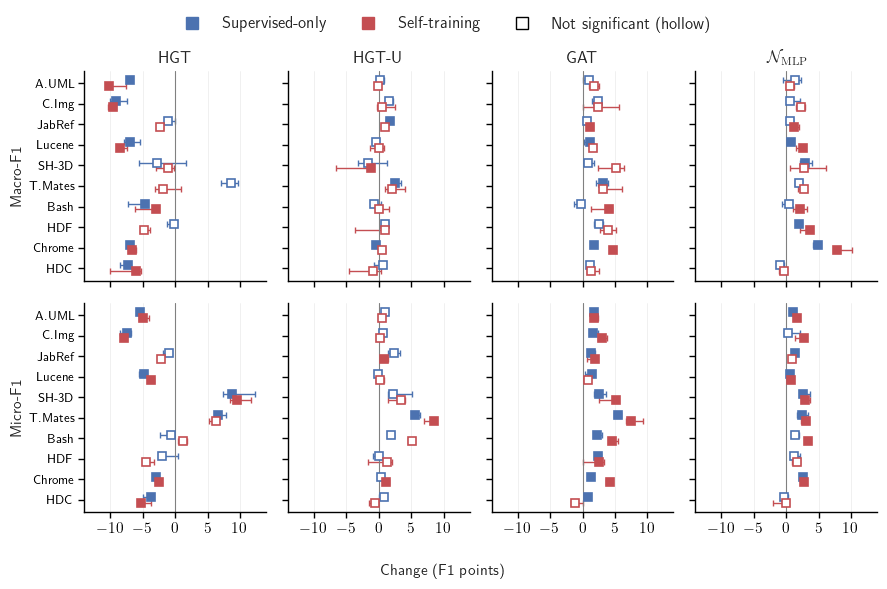

In [32]:
def fig_onoff(t, rep="N2V", name=None):
    d = t[t.rep == rep]
    fig, axes = plt.subplots(2, 4, figsize=(9, 5.5), sharey=True, sharex=True)
    y0 = np.arange(len(SYSTEMS))
    for r_, (metric, mname) in enumerate([("macro", "Macro-F1"), ("micro", "Micro-F1")]):
        for c_, (m, title) in enumerate(MODELS):
            ax = axes[r_, c_]
            for j, s in enumerate(["sup", "self"]):
                g = d[(d.model == m) & (d.schedule == s) & (d.metric == metric)].set_index("system").reindex(SYSTEMS)
                y = y0 + (j - 0.5) * 0.28
                ax.errorbar(g["median"], y, xerr=[g["median"] - g.smin, g.smax - g["median"]], fmt="none",
                            ecolor=SCHED_COLOR[s], elinewidth=1, capsize=2, zorder=2)
                for yi, (_, row) in zip(y, g.iterrows()):
                    ax.plot(row["median"], yi, "s", color=SCHED_COLOR[s],
                            mfc=SCHED_COLOR[s] if row.sig else "white", mew=1.2, ms=5.5, zorder=3)
            ax.axvline(0, color="grey", lw=0.8)
            if r_ == 0:
                ax.set_title(title,fontweight="bold",fontsize=12)
        axes[r_, 0].set_ylabel(mname, fontsize=11)
    axes[0, 0].set_yticks(y0, [LAB.get(s, s) for s in SYSTEMS])
    axes[0, 0].invert_yaxis()
    lim = int(np.ceil(np.nanmax(np.abs(d[["smin", "smax"]].values)))) + 1
    ticks = np.arange(-(lim // 5) * 5, (lim // 5) * 5 + 1, 5)
    axes[1, 0].set_xticks(ticks)
    axes[1, 0].set_xlim(-lim, lim)
    fig.supxlabel("Change (F1 points)", fontsize=11)
    h = [Line2D([], [], marker="s", color=SCHED_COLOR["sup"], ls="", mfc=SCHED_COLOR["sup"], label=SCHED_LABEL["sup"]),
         Line2D([], [], marker="s", color=SCHED_COLOR["self"], ls="", mfc=SCHED_COLOR["self"], label=SCHED_LABEL["self"]),
         Line2D([], [], marker="s", color="black", ls="", mfc="white", label="Not significant (hollow)")]
    fig.legend(handles=h, loc="upper center", bbox_to_anchor=(0.5, 1.06), ncol=len(h), fontsize=12, frameon=False,
               markerscale=1.5, columnspacing=1.5)
    for ax in axes.flat:
        ax.tick_params(axis="y", labelsize=9)
    fig.tight_layout()
    save_fig(fig, name or f"rq3_{rep}")
    plt.show()


fig_onoff(sys_tab, "N2V")

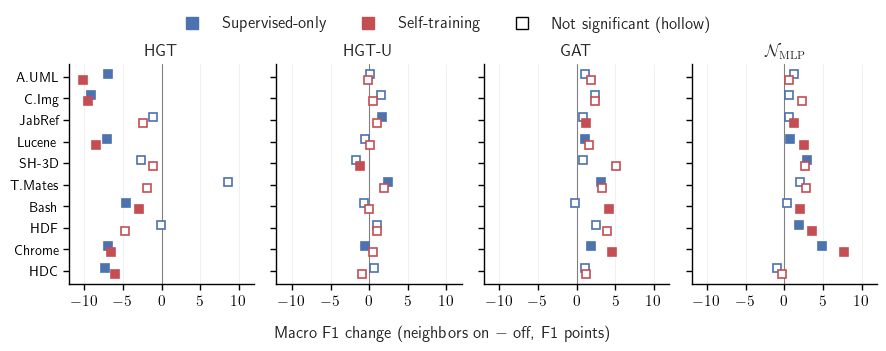

In [33]:
def fig_onoff(t, rep="N2V", metric="macro", name=None):
    d = t[(t.rep == rep) & (t.metric == metric)]
    fig, axes = plt.subplots(1, 4, figsize=(9, 3.3), sharey=True, sharex=True)
    y0 = np.arange(len(SYSTEMS))
    for c_, (m, title) in enumerate(MODELS):
        ax = axes[c_]
        for j, s in enumerate(["sup", "self"]):
            g = d[(d.model == m) & (d.schedule == s)].set_index("system").reindex(SYSTEMS)
            y = y0 + (j - 0.5) * 0.28
            for yi, (_, row) in zip(y, g.iterrows()):
                ax.plot(row["median"], yi, "s", color=SCHED_COLOR[s],
                        mfc=SCHED_COLOR[s] if row.sig else "white", mew=1.2, ms=5.5, zorder=3)
        ax.axvline(0, color="grey", lw=0.8)
        ax.set_title(title, fontweight="bold", fontsize=12)
        ax.tick_params(axis="y", labelsize=10)
    axes[0].set_yticks(y0, [LAB.get(s, s) for s in SYSTEMS])
    axes[0].invert_yaxis()
    lim = int(np.ceil(np.nanmax(np.abs(d["median"].values)))) + 1
    ticks = np.arange(-(lim // 5) * 5, (lim // 5) * 5 + 1, 5)
    axes[0].set_xticks(ticks)
    axes[0].set_xlim(-lim, lim)
    fig.supxlabel("Macro F1 change (neighbors on $-$ off, F1 points)", fontsize=12, y=0.05)
    h = [Line2D([], [], marker="s", color=SCHED_COLOR["sup"], ls="", mfc=SCHED_COLOR["sup"], label=SCHED_LABEL["sup"]),
         Line2D([], [], marker="s", color=SCHED_COLOR["self"], ls="", mfc=SCHED_COLOR["self"], label=SCHED_LABEL["self"]),
         Line2D([], [], marker="s", color="black", ls="", mfc="white", label="Not significant (hollow)")]
    fig.legend(handles=h, loc="upper center", bbox_to_anchor=(0.5, 1.08), ncol=len(h), fontsize=12, frameon=False,
               markerscale=1.5, columnspacing=1.5)
    fig.tight_layout()
    save_fig(fig, name or "rq3_n2v")
    plt.show()


fig_onoff(sys_tab, "N2V")

### 5.2 Which predictor is best, by input vector

Absolute F1 with neighbors on (HGT, GAT, neighbor MLP) and the feature-only MLP as reference.
Boxes: all runs pooled; dots: one per system (that system's median); tiles: median over systems (best in bold).

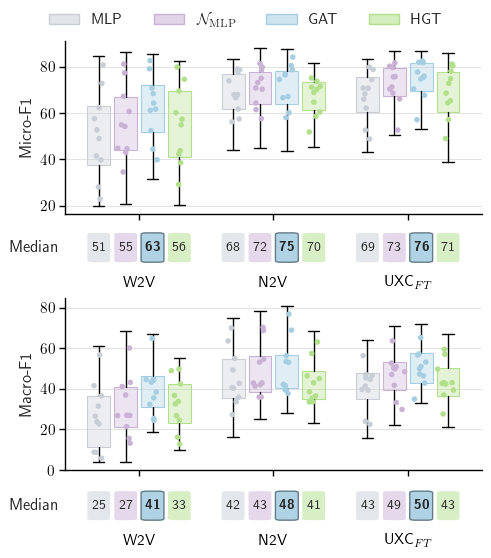

In [34]:
def assign_method(df):
    df = df.copy()
    # labels are listed in the SAME order as the conditions; ORDER (display order) must not be used here
    df["method"] = np.select([(df.model == "MLP") & ~df.neighbors, (df.model == "HGT") & df.neighbors,
                              (df.model == "GAT") & df.neighbors, (df.model == "MLP") & df.neighbors],
                             ["MLP0", "HGT", "GAT", "MLPN"], default="")
    return df[df.method != ""]


meth = assign_method(runs)
# guard: every label holds exactly the runs of its own model and neighbor setting
for _m, _mod, _on in [("MLP0", "MLP", False), ("HGT", "HGT", True), ("GAT", "GAT", True), ("MLPN", "MLP", True)]:
    _a = meth[meth.method == _m][["system", "rep", "schedule", "seed", "split", "f1_macro"]].sort_values(
        ["system", "rep", "schedule", "seed", "split"]).f1_macro.to_numpy()
    _b = runs[(runs.model == _mod) & (runs.neighbors == _on)][["system", "rep", "schedule", "seed", "split", "f1_macro"]].sort_values(
        ["system", "rep", "schedule", "seed", "split"]).f1_macro.to_numpy()
    assert np.array_equal(_a, _b), _m

def fig_compare(sched=SCHED, name=None):
    allr = meth[meth.schedule == sched]
    off = np.linspace(-0.3, 0.3, 4)
    rng = np.random.default_rng(0)

    fig = plt.figure(figsize=(4.8, 5.5), layout="constrained")
    outer = fig.add_gridspec(2, 1, hspace=0.12)

    for row, (metric, mname) in enumerate(METRICS):
        inner = outer[row].subgridspec(
            2, 1, height_ratios=[1.8, 0.4], hspace=0.03
        )
        ax = fig.add_subplot(inner[0])
        ab = fig.add_subplot(inner[1])  # Separate axis so median tiles don't hide input labels.

        for g, rep in enumerate(REPS):
            for i, (m, _, c) in enumerate(METHODS):
                sel = allr[(allr.rep == rep) & (allr.method == m)]
                pts = sel.groupby("system")[metric].median().to_numpy()

                bp = ax.boxplot(
                    sel[metric].to_numpy(),
                    positions=[g + off[i]],
                    widths=0.17,
                    showfliers=False,
                    patch_artist=True,
                    medianprops={"color": "none", "linewidth": 0},
                )
                bp["boxes"][0].set_facecolor(to_rgba(c, 0.35))
                bp["boxes"][0].set_edgecolor(to_rgba(c, 1.0))
                bp["boxes"][0].set_linewidth(0.8)

                ax.scatter(
                    g + off[i] + rng.normal(0, 0.025, len(pts)),
                    pts,
                    s=16,
                    alpha=1,
                    color=c,
                    edgecolors="none",
                    zorder=3,
                )

        ax.set_ylabel(mname)
        # ax.tick_params(axis="x", bottom=False, labelbottom=False)
        ax.set_xticks(range(len(REPS)))
        ax.tick_params(axis="x", bottom=True, labelbottom=False)
        ax.set_xlim(-0.55, len(REPS) - 0.45)
        ab.set_xlim(-0.55, len(REPS) - 0.45)
        ax.xaxis.grid(False)
        ax.yaxis.grid(True, alpha=0.8, linestyle="-")

        meds = (
            allr.groupby(["rep", "method", "system"])[metric]
            .median()
            .groupby(["rep", "method"])
            .median()
        )

        for g, rep in enumerate(REPS):
            vals = [meds[(rep, m)] for m in ORDER]
            best = int(np.argmax(vals))

            for i, (m, _, c) in enumerate(METHODS):
                is_best = i == best
                ab.add_patch(
                    FancyBboxPatch(
                        (g + off[i] - 0.085, 0.12),
                        0.17,
                        0.76,
                        boxstyle="round,pad=0,rounding_size=0.04",
                        facecolor=to_rgba(c, alpha=0.9 if is_best else 0.5),
                        edgecolor=tuple(x * 0.6 for x in to_rgba(c)[:3])
                        if is_best else "none",
                        linewidth=1.0,
                    )
                )
                txt = f"{vals[i]:.0f}"
                ab.text(
                    g + off[i],
                    0.5,
                    bold(txt) if is_best else txt,
                    ha="center",
                    va="center",
                    fontsize=10,
                )

        ab.set_ylim(0, 1)
        ab.grid(False)
        ab.set_xticks(
            range(len(REPS)),
            [REP_LABEL[r_] for r_ in REPS],
        )
        ab.tick_params(
            axis="x",
            bottom=False,
            labelbottom=True,
            # length=3,
            pad=3,
        )
        ab.set_yticks([])
        ab.set_ylabel("Median", rotation=0, ha="right", va="center")
        for spine in ab.spines.values():
            spine.set_visible(False)

    handles = [
        plt.Rectangle(
            (0, 0), 1, 1,
            facecolor=to_rgba(c, 0.55),
            edgecolor=to_rgba(c, 1.0),
        )
        for _, _, c in METHODS
    ]
    fig.legend(handles, LABELS, loc="outside upper center", ncol=4, frameon=False)
    save_fig(fig, name or f"rq3_fig_compare_{sched}")
    plt.show()


fig_compare(SCHED)

### 100-run check: feature-only MLP vs HGT (RQ1/RQ2 data)

Self-training, 100 runs per system. Not comparable with the supervised-only ten-split figure above. The following comparison uses the 100-run Neighbor MLP and HGT results, plus the 100-split GAT results. HGT and Neighbor MLP are available for W2V, N2V, and UXC_FT; GAT also includes UXC_ZS.

In [35]:
ROOT

WindowsPath('c:/Users/JABEERAK/Architecture_Recovery/HetMap')

   rep   metric  median_diff  hgt_higher  sig_up  sig_down
   W2V f1_micro         1.22           6       6         4
   W2V f1_macro         1.59           6       6         3
   N2V f1_micro        -3.22           2       2         7
   N2V f1_macro        -2.91           1       1         6
UXC_FT f1_micro         0.97           6       6         1
UXC_FT f1_macro         2.79           8       5         1


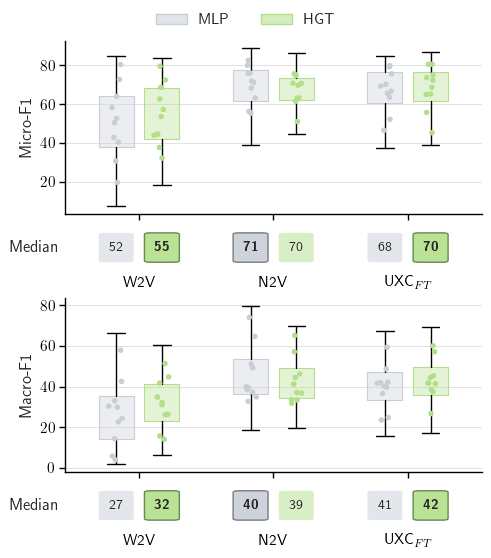

In [38]:
# 100-run check (RQ1/RQ2 data): feature-only MLP vs HGT (file graph, "F"), self-training, no on/off ablation.
# Zero-shot has no 100-run HGT result, so only W2V, N2V and UXC_FT are shown.
R100 = ROOT / "results"
SRC100 = {"W2V": ("HGT_W2V/MLP", "HGT_W2V/File_only"),
          "N2V": ("HGT_N2V/MLP", "HGT_N2V/File_only"),
          "UXC_FT": ("HGT_UXC/MLP_file_ft", "HGT_UXC/File_only")}
M100 = [m for m in METHODS if m[0] in ("MLP0", "HGT")]
REPS100 = list(SRC100)

_rows = []
for rep, (mlp_dir, hgt_dir) in SRC100.items():
    for method, d in (("MLP0", mlp_dir), ("HGT", hgt_dir)):
        for s in SYSTEMS:
            x = pd.read_csv(R100 / d / f"{s}.csv")[["run_id", "f1_macro", "f1_micro"]]
            _rows.append(x.assign(system=s, rep=rep, method=method))
r100 = pd.concat(_rows, ignore_index=True)
assert r100.groupby(["rep", "method", "system"]).size().eq(100).all()          # 100 runs everywhere

# Save all 100-run HGT scores in long format across W2V, N2V, and UXC_FT.
h100_long = r100[r100.method == "HGT"][["system", "rep", "run_id", "method", "f1_macro", "f1_micro"]]
h100_long.to_csv(ROOT / "results" / "RQ3" / "hgt_100runs_long.csv", index=False)

# summary + paired test per system (pairing by run_id), Holm across the ten systems
_summ = []
for rep in REPS100:
    for metric, mname in METRICS:
        d, p = [], []
        for s in SYSTEMS:
            g = r100[(r100.rep == rep) & (r100.system == s)].pivot(index="run_id", columns="method", values=metric)
            diff = (g["HGT"] - g["MLP0"]).to_numpy()
            d.append(g["HGT"].median() - g["MLP0"].median()); p.append(pval(diff))      # difference of medians, as in RQ2
        d, adj = np.array(d), holm(p)
        _summ.append(dict(rep=rep, metric=metric, median_diff=round(float(np.median(d)), 2), hgt_higher=int((d > 0).sum()),
                           sig_up=int(((adj < ALPHA) & (d > 0)).sum()), sig_down=int(((adj < ALPHA) & (d < 0)).sum())))
summ100 = pd.DataFrame(_summ)
print(summ100.to_string(index=False))

# consistency with the RQ2 table (F - MLP, ten systems)
_rq2 = pd.read_csv(ROOT / "results" / "Statiscal_Test" / "tables" / "rq2_steps_cells.csv")
_rq2 = _rq2[_rq2.step.str.contains("MLP")].set_index(["rep", "metric"])["median"]
for _, r_ in summ100.iterrows():
    key = ("UXC" if r_.rep == "UXC_FT" else r_.rep, r_.metric)
    assert abs(_rq2[key] - r_.median_diff) < 0.07, (key, _rq2[key], r_.median_diff)


def fig_boxes(df, methods, labels, name, reps=REPS100, ncol=2):
    off = np.linspace(-0.3, 0.3, len(methods)) if len(methods) > 2 else np.linspace(-0.17, 0.17, len(methods))
    w = 0.17 if len(methods) > 2 else 0.26
    rng = np.random.default_rng(0)
    fig = plt.figure(figsize=(4.8, 5.5), layout="constrained")
    outer = fig.add_gridspec(2, 1, hspace=0.12)
    for row, (metric, mname) in enumerate(METRICS):
        inner = outer[row].subgridspec(2, 1, height_ratios=[1.8, 0.4], hspace=0.03)
        ax = fig.add_subplot(inner[0])
        ab = fig.add_subplot(inner[1])
        for g, rep in enumerate(reps):
            for i, (m, _, c) in enumerate(methods):
                sel = df[(df.rep == rep) & (df.method == m)]
                pts = sel.groupby("system")[metric].median().to_numpy()
                bp = ax.boxplot(sel[metric].to_numpy(), positions=[g + off[i]], widths=w, showfliers=False,
                                patch_artist=True, medianprops={"color": "none", "linewidth": 0})
                bp["boxes"][0].set_facecolor(to_rgba(c, 0.35))
                bp["boxes"][0].set_edgecolor(to_rgba(c, 1.0))
                bp["boxes"][0].set_linewidth(0.8)
                ax.scatter(g + off[i] + rng.normal(0, 0.025, len(pts)), pts, s=16, alpha=1, color=c,
                           edgecolors="none", zorder=3)
        ax.set_ylabel(mname)
        ax.set_xticks(range(len(reps)))
        ax.tick_params(axis="x", bottom=True, labelbottom=False)
        ax.set_xlim(-0.55, len(reps) - 0.45)
        ab.set_xlim(-0.55, len(reps) - 0.45)
        ax.xaxis.grid(False)
        ax.yaxis.grid(True, alpha=0.8, linestyle="-")
        meds = df.groupby(["rep", "method", "system"])[metric].median().groupby(["rep", "method"]).median()
        for g, rep in enumerate(reps):
            vals = [meds[(rep, m)] for m, _, _ in methods]
            best = int(np.argmax(vals))
            for i, (m, _, c) in enumerate(methods):
                is_best = i == best
                ab.add_patch(FancyBboxPatch((g + off[i] - w / 2, 0.12), w, 0.76,
                                            boxstyle="round,pad=0,rounding_size=0.04",
                                            facecolor=to_rgba(c, alpha=0.9 if is_best else 0.5),
                                            edgecolor=tuple(x * 0.6 for x in to_rgba(c)[:3]) if is_best else "none",
                                            linewidth=1.0))
                txt = f"{vals[i]:.0f}"
                ab.text(g + off[i], 0.5, bold(txt) if is_best else txt, ha="center", va="center", fontsize=10)
        ab.set_ylim(0, 1)
        ab.grid(False)
        ab.set_xticks(range(len(reps)), [REP_LABEL[r_] for r_ in reps])
        ab.tick_params(axis="x", bottom=False, labelbottom=True, pad=3)
        ab.set_yticks([])
        ab.set_ylabel("Median", rotation=0, ha="right", va="center")
        for spine in ab.spines.values():
            spine.set_visible(False)
    handles = [plt.Rectangle((0, 0), 1, 1, facecolor=to_rgba(c, 0.55), edgecolor=to_rgba(c, 1.0)) for _, _, c in methods]
    fig.legend(handles, labels, loc="outside upper center", ncol=ncol, frameon=False)
    save_fig(fig, name)
    plt.show()


# (a) MLP vs HGT, both 100 runs, self-training (RQ1/RQ2 data)
fig_boxes(r100, M100, [l for _, l, _ in M100], "rq3_fig_compare_100")



In [40]:
ROOT

WindowsPath('c:/Users/JABEERAK/Architecture_Recovery/HetMap')

In [ ]:
# Compare 100-run predictors; add supervised-only HGT for UXC_FT as its own series.
RQ3DIR = ROOT / "results" / "RQ3"

nmlp = pd.read_csv(
    RQ3DIR / "neighbour-mlp-supervised_100splits.csv",
    usecols=["system", "representation", "run_id", "f1_macro", "f1_micro"],
)
nmlp = nmlp.rename(columns={"representation": "rep"}).assign(method="MLPN")
assert nmlp.groupby(["rep", "system"]).size().eq(100).all()
assert set(nmlp.rep.unique()) == set(REPS100)

g100 = pd.read_csv(
    RQ3DIR / "residual_gat_100splits.csv",
    usecols=["system", "representation", "split_id", "mode", "f1_macro", "f1_micro"],
)
g100 = g100.rename(columns={"representation": "rep", "split_id": "run_id"})
assert g100["mode"].eq("GAT").all()
g100 = g100[g100.rep.isin(REPS100)].assign(method="GAT")
assert g100.groupby(["rep", "system"]).size().eq(100).all()

HSUP_PATH = ROOT / "RQ3_final_check" / "hgt_neighbor_mlp_100splits" / "hgt_neighbor_mlp_100splits_long.csv"
hsup = pd.read_csv(HSUP_PATH)
hsup = hsup[(hsup.model == "HGT") & (hsup.representation == "UXC_FT")]
assert hsup.schedule.eq("supervised190").all() and hsup.epochs.eq(190).all()
assert hsup.groupby("system").size().eq(100).all()
hsup = hsup.rename(columns={"representation": "rep"}).assign(method="HGT")

mix = pd.concat(
    [
        # r100[r100.method == "MLP0"][["system", "rep", "run_id", "method", "f1_macro", "f1_micro"]],
        hsup[["system", "rep", "run_id", "method", "f1_macro", "f1_micro"]],
        g100[["system", "rep", "run_id", "method", "f1_macro", "f1_micro"]],
        nmlp[["system", "rep", "run_id", "method", "f1_macro", "f1_micro"]],
    ],
    ignore_index=True,
)
assert mix.groupby(["rep", "method", "system"]).size().eq(100).all()
assert not mix.duplicated(["rep", "method", "system", "run_id"]).any()

for _me, _nm in METRICS:
    print(_nm)
    print(
        mix.groupby(["rep", "method", "system"])[_me]
        .median()
        .groupby(["rep", "method"])
        .median()
        .unstack()
        .reindex(columns=["MLPN", "GAT", "HGT"])
        .round(1)
    )

MIX_METHODS = [m for m in METHODS if m[0] in ("MLPN", "GAT")] + [("HGT", "HGT (100, sup., UXC$_{FT}$)", "#B2DF8A")]
MIX_REPS = [rep for rep in REPS100 if rep in set(mix.rep)]
MIX_OFF = np.linspace(-0.22, 0.22, len(MIX_METHODS))
MIX_WIDTH = 0.18
_rng = np.random.default_rng(0)
_fig = plt.figure(figsize=(7.0, 6.0), layout="constrained")
_outer = _fig.add_gridspec(2, 1, hspace=0.12)
for _row, (_metric, _metric_name) in enumerate(METRICS):
    _inner = _outer[_row].subgridspec(2, 1, height_ratios=[1.8, 0.4], hspace=0.03)
    _ax = _fig.add_subplot(_inner[0])
    _ab = _fig.add_subplot(_inner[1])
    _meds = mix.groupby(["rep", "method", "system"])[_metric].median().groupby(["rep", "method"]).median()
    for _g, _rep in enumerate(MIX_REPS):
        _available = []
        for _i, (_method, _label, _color) in enumerate(MIX_METHODS):
            _sel = mix[(mix.rep == _rep) & (mix.method == _method)]
            _x = _g + MIX_OFF[_i]
            if _sel.empty:
                _ax.text(_x, 0.025, "n/a", transform=_ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=7)
                _ab.text(_x, 0.5, "n/a", ha="center", va="center", fontsize=6)
                continue
            _bp = _ax.boxplot(_sel[_metric].to_numpy(), positions=[_x], widths=MIX_WIDTH, showfliers=False,
                              patch_artist=True, medianprops={"color": "none", "linewidth": 0})
            _bp["boxes"][0].set_facecolor(to_rgba(_color, 0.35))
            _bp["boxes"][0].set_edgecolor(to_rgba(_color, 1.0))
            _bp["boxes"][0].set_linewidth(0.8)
            _pts = _sel.groupby("system")[_metric].median().to_numpy()
            _ax.scatter(_x + _rng.normal(0, 0.018, len(_pts)), _pts, s=13, color=_color, edgecolors="none", zorder=3)
            _available.append((_i, _method, _meds[(_rep, _method)]))
        _best = max(_available, key=lambda _x: _x[2])[0]
        for _i, _method, _value in _available:
            _color = MIX_METHODS[_i][2]
            _is_best = _i == _best
            _ab.add_patch(FancyBboxPatch((_g + MIX_OFF[_i] - MIX_WIDTH / 2, 0.12), MIX_WIDTH, 0.76,
                         boxstyle="round,pad=0,rounding_size=0.04", facecolor=to_rgba(_color, 0.9 if _is_best else 0.5),
                         edgecolor=tuple(_v * 0.6 for _v in to_rgba(_color)[:3]) if _is_best else "none", linewidth=1.0))
            _txt = f"{_value:.0f}"
            _ab.text(_g + MIX_OFF[_i], 0.5, bold(_txt) if _is_best else _txt, ha="center", va="center", fontsize=8)
    _ax.set_ylabel(_metric_name)
    _ax.set_xlim(-0.55, len(MIX_REPS) - 0.45)
    _ax.set_xticks(range(len(MIX_REPS)))
    _ax.tick_params(axis="x", labelbottom=False)
    _ax.yaxis.grid(True, alpha=0.8)
    _ab.set_xlim(-0.55, len(MIX_REPS) - 0.45)
    _ab.set_ylim(0, 1)
    _ab.set_xticks(range(len(MIX_REPS)), [REP_LABEL[rep] for rep in MIX_REPS])
    _ab.set_yticks([])
    _ab.set_ylabel("Median", rotation=0, ha="right", va="center")
    for _spine in _ab.spines.values():
        _spine.set_visible(False)
_handles = [plt.Rectangle((0, 0), 1, 1, facecolor=to_rgba(color, 0.55), edgecolor=to_rgba(color, 1.0))
            for _, _, color in MIX_METHODS]
_fig.legend(_handles, [label for _, label, _ in MIX_METHODS], loc="outside upper center", ncol=3, frameon=False)
save_fig(_fig, "rq3_fig_compare_100_mixed")
plt.show()

In [42]:
g100

,system,rep,split_id,mode,f1_micro,f1_macro,method


### 5.3 Predictors per system (all systems in one column; run-to-run variability)

Choose the vector with `REP_SHOW` and the metrics with `SHOW`.

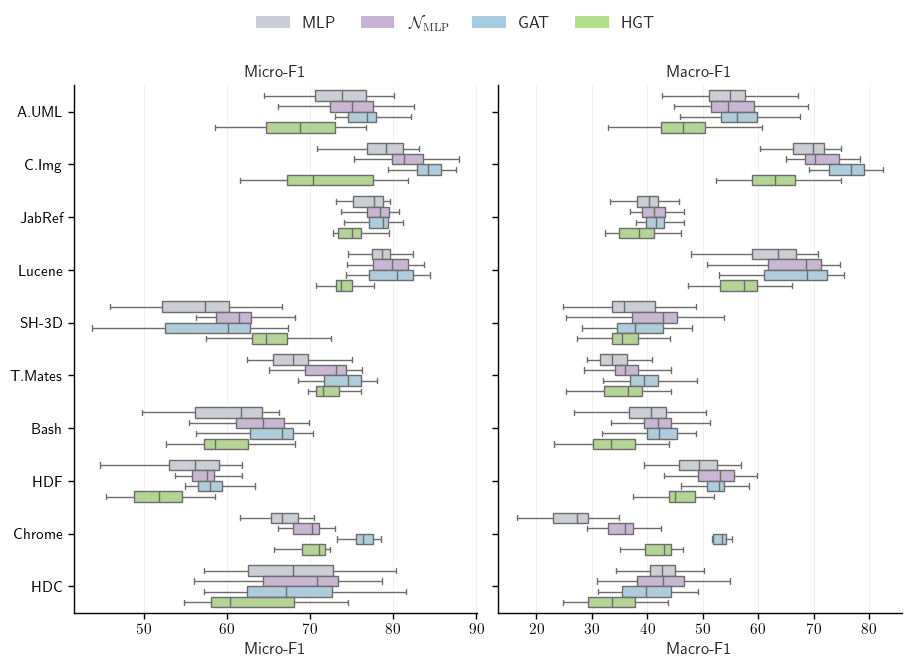

In [14]:
REP_SHOW = "N2V"
SHOW = ["f1_macro", "f1_micro"]            # e.g. ["f1_macro"]

def fig_per_system(rep=REP_SHOW, sched=SCHED, show=SHOW, name=None):
    sub = meth[(meth.rep == rep) & (meth.schedule == sched)]
    sel = [(m, n) for m, n in METRICS if m in show]
    fig, axes = plt.subplots(1, len(sel), figsize=(4.5 * len(sel), 6), sharey=True,
                             constrained_layout=True, squeeze=False)
    for ax, (metric, mname) in zip(axes[0], sel):
        sns.boxplot(data=sub, y="system", x=metric, order=SYSTEMS, hue="method", hue_order=ORDER, palette=PASTEL,
                    orient="h", showfliers=False, ax=ax)
        ax.get_legend().remove()
        ax.set_title(mname)
        ax.set_xlabel(mname)
        ax.set_ylabel("")
    axes[0, 0].set_yticks(range(len(SYSTEMS)), [LAB.get(s, s) for s in SYSTEMS])
    handles = [Patch(facecolor=PASTEL[m], edgecolor="none") for m in ORDER]
    fig.legend(handles=handles, labels=LABELS, loc="upper center", bbox_to_anchor=(0.5, 1.1), ncol=len(handles),
               fontsize=12, frameon=False, columnspacing=1.5)
    save_fig(fig, name or f"rq3_fig_per_system_{rep}_{sched}")
    plt.show()


from matplotlib.patches import Patch
fig_per_system()

### 5.4 Summary heatmap (median change, systems improving)

Same numbers as the paper's summary table: median change across the systems in macro-F1 points, with the
number of systems that improve in parentheses.

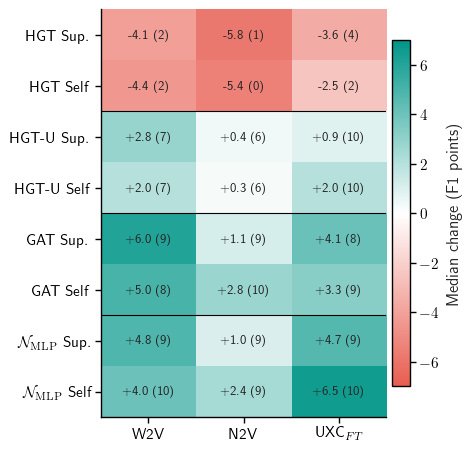

In [15]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
cmap_gl = LinearSegmentedColormap.from_list("lossgain", ["#E85D50", "#FFFFFF", "#009688"])   # coral = loss, teal = gain (as in the paper table)


def fig_heatmap(metric="macro", name=None):
    t = reps_tab[reps_tab.metric == metric]
    rows = [(m, s) for m, _ in MODELS for s in ("sup", "self")]
    fig, ax = plt.subplots(figsize=(4.6, 4.4), constrained_layout=True)
    M = np.zeros((len(rows), len(REPS)))
    P = np.zeros_like(M, dtype=int)
    for i, (m, s) in enumerate(rows):
        for j, rep in enumerate(REPS):
            r_ = t[(t.rep == rep) & (t.model == m) & (t.schedule == s)].iloc[0]
            M[i, j], P[i, j] = r_["median"], int(r_.pos)
    im = ax.imshow(M, cmap=cmap_gl, norm=TwoSlopeNorm(vmin=-7, vcenter=0, vmax=7), aspect="auto")
    for i in range(len(rows)):
        for j in range(len(REPS)):
            ax.text(j, i, f"{M[i, j]:+.1f} ({P[i, j]})", ha="center", va="center", fontsize=9)
    ax.set_xticks(range(len(REPS)), [REP_LABEL[r_] for r_ in REPS])
    names = dict(MODELS)
    ax.set_yticks(range(len(rows)), [f"{names[m]} {'Sup.' if s == 'sup' else 'Self'}" for m, s in rows])
    for k in range(1, len(MODELS)):
        ax.axhline(2 * k - 0.5, color="black", lw=0.8)
    ax.grid(False)
    cb = fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02)
    cb.set_label("Median change (F1 points)")
    save_fig(fig, name or f"rq3_fig_heatmap_{metric}")
    plt.show()


fig_heatmap("macro")

### 5.5 Self-training minus supervised-only (neighbors on)

Per-system median of the paired difference for each predictor. The macro-F1 loss comes with a fall in macro recall
while micro-F1 and macro precision stay close: consistent with pseudo-labels favoring large modules
(not tested directly; no class weighting is used).

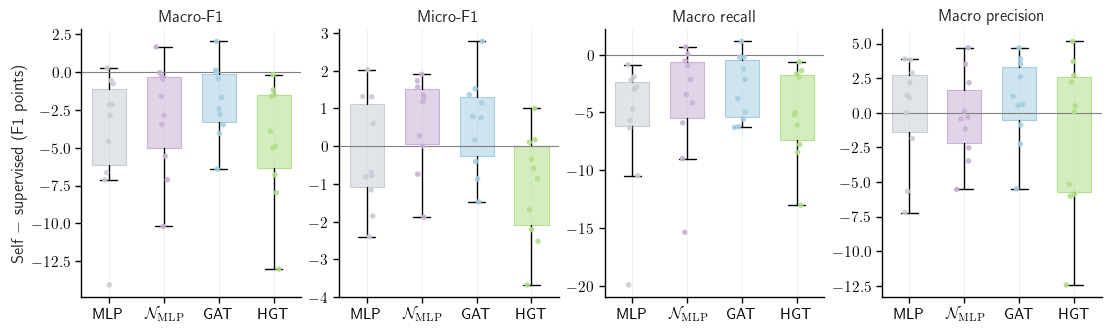

        f1_macro  f1_micro  recall_macro  precision_macro
method                                                   
GAT        -2.06      0.77         -2.96             0.90
HGT        -4.41     -0.73         -5.10             0.28
MLP0       -2.52     -0.74         -3.86             1.18
MLPN       -2.25      1.24         -2.80            -0.39


In [16]:
def fig_schedule(rep="N2V", name=None):
    keys = ["system", "rep", "method", "seed", "split"]
    cols = ["f1_macro", "f1_micro", "recall_macro", "precision_macro"]
    w = meth[meth.rep == rep].pivot_table(index=keys, columns="schedule", values=cols)
    d = pd.DataFrame({c: w[(c, "self")] - w[(c, "sup")] for c in cols}).reset_index()
    per = d.groupby(["method", "system"])[cols].median().reset_index()
    titles = {"f1_macro": "Macro-F1", "f1_micro": "Micro-F1", "recall_macro": "Macro recall", "precision_macro": "Macro precision"}
    fig, axes = plt.subplots(1, 4, figsize=(11, 3.2), sharey=False, constrained_layout=True)
    rng = np.random.default_rng(0)
    for ax, c in zip(axes, cols):
        vals = [per[per.method == m][c].to_numpy() for m in ORDER]
        bp = ax.boxplot(vals, positions=range(4), widths=0.62, showfliers=False, patch_artist=True,
                        medianprops={"color": "none", "linewidth": 0})
        for i, (m, _, col) in enumerate(METHODS):
            bp["boxes"][i].set_facecolor(to_rgba(col, 0.55))
            bp["boxes"][i].set_edgecolor(to_rgba(col, 1.0))
            bp["boxes"][i].set_linewidth(0.8)
            ax.scatter(i + rng.normal(0, 0.06, len(vals[i])), vals[i], s=16, alpha=0.9, color=col,
                       edgecolors="none", zorder=3)
        ax.axhline(0, color="grey", lw=0.8)
        ax.set_title(titles[c])
        ax.set_xticks(range(4), LABELS)
    axes[0].set_ylabel("Self $-$ supervised (F1 points)")
    save_fig(fig, name or f"rq3_fig_schedule_{rep}")
    plt.show()
    return per


sched_per = fig_schedule("N2V")
print(sched_per.groupby("method")[["f1_macro", "f1_micro", "recall_macro", "precision_macro"]].median().round(2))

## 6. Variability and where each predictor is better

* **Variability:** spread over splits (median IQR within a seed), range of the seed medians (N2V only), standard
  deviation over all runs, for each predictor, system, vector and schedule.
* **Wins:** the predictor with the highest median per system, and counts per vector and schedule.
* **Head to head:** paired difference between two predictors per system (average over seeds per split), exact
  signed-rank with Holm across systems.

In [17]:
rows = []
for (rep, sched, sy, m), g in meth.groupby(["rep", "schedule", "system", "method"]):
    for metric in ["f1_macro", "f1_micro"]:
        by_seed = g.groupby("seed")[metric]
        iqr = by_seed.apply(lambda x: x.quantile(0.75) - x.quantile(0.25)).median()
        seed_med = by_seed.median()
        rows.append(dict(rep=rep, schedule=sched, system=sy, method=m, metric=metric.replace("f1_", ""),
                         median=g[metric].median(), iqr_splits=iqr, seed_range=seed_med.max() - seed_med.min(),
                         std_all=g[metric].std(), n_runs=len(g)))
variab = pd.DataFrame(rows)
variab.to_csv(OUT / "rq3_variability.csv", index=False)

winners = (variab.loc[variab.groupby(["rep", "schedule", "system", "metric"])["median"].idxmax()]
           [["rep", "schedule", "system", "metric", "method", "median"]])
wins = winners.groupby(["rep", "schedule", "metric", "method"]).size().rename("systems_won").reset_index()
wins.to_csv(OUT / "rq3_wins.csv", index=False)
display(wins[(wins.schedule == SCHED) & (wins.metric == "macro")].pivot_table(index="rep", columns="method",
                                                                              values="systems_won", fill_value=0))
display(variab[(variab.schedule == SCHED) & (variab.metric == "macro")]
        .groupby(["rep", "method"])[["iqr_splits", "seed_range"]].median().round(2))

method,GAT,HGT,MLPN
rep,,,
N2V,7.0,0.0,3.0
UXC_FT,7.0,1.0,2.0
W2V,8.0,2.0,0.0


iqr_splits  seed_range
rep    method                        
N2V    GAT           4.99        1.52
       HGT           6.15        1.55
       MLP0          5.10        2.04
       MLPN          5.82        1.50
UXC_FT GAT           8.01        0.00
       HGT           7.19        0.00
       MLP0          5.92        0.00
       MLPN          5.63        0.00
W2V    GAT           6.45        0.00
       HGT           3.81        0.00
       MLP0          4.65        0.00
       MLPN          3.74        0.00

In [18]:
PAIRS = [("GAT", "HGT"), ("MLPN", "HGT"), ("GAT", "MLPN"), ("GAT", "MLP0"), ("HGT", "MLP0"), ("MLPN", "MLP0")]


def head_to_head(rep, sched, a, b, metric):
    w = meth[(meth.rep == rep) & (meth.schedule == sched)].pivot_table(
        index=["system", "seed", "split"], columns="method", values=metric)
    rows = []
    for sy, g in w.groupby(level="system"):
        diff = (g[a] - g[b]).droplevel("system")
        rows.append(dict(system=sy, median=diff.groupby(level="seed").median().median(),
                         p=pval(diff.groupby(level="split").mean().values)))
    t = pd.DataFrame(rows)
    t["p_holm"] = holm(t.p.values)
    return dict(rep=rep, schedule=sched, metric=metric.replace("f1_", ""), a=a, b=b, n_sys=len(t),
                median_gap=t["median"].median(), a_higher=int((t["median"] > 1e-9).sum()),
                sig_a=int(((t.p_holm < ALPHA) & (t["median"] > 0)).sum()),
                sig_b=int(((t.p_holm < ALPHA) & (t["median"] < 0)).sum()))


h2h = pd.DataFrame([head_to_head(rep, s, a, b, me) for rep in REPS for s in ("sup", "self")
                    for a, b in PAIRS for me in ("f1_macro", "f1_micro")])
h2h.to_csv(OUT / "rq3_head_to_head.csv", index=False)
display(h2h[(h2h.schedule == SCHED) & (h2h.metric == "macro") & (h2h.rep == "N2V")].round(2))

,rep,schedule,metric,a,b,n_sys,median_gap,a_higher,sig_a,sig_b
36,N2V,self,macro,GAT,HGT,10,6.79,10,7,0
38,N2V,self,macro,MLPN,HGT,10,7.59,9,7,1
40,N2V,self,macro,GAT,MLPN,10,0.85,6,2,0
42,N2V,self,macro,GAT,MLP0,10,2.87,9,4,0
44,N2V,self,macro,HGT,MLP0,10,-5.09,2,1,4
46,N2V,self,macro,MLPN,MLP0,10,2.44,9,5,0


## 7. Counts quoted in the text

In [19]:
counts = []
add = lambda k, v: counts.append((k, v))

# fit totals (final-stage rows)
n_hgt_mlp = len(runs[(runs.rep == "N2V") & runs.model.isin(["HGT", "uHGT", "MLP"])])
n_gat = len(runs[(runs.rep == "N2V") & (runs.model == "GAT")])
n_emb = len(runs[runs.rep != "N2V"])
add("fits N2V (HGT, uHGT, neighbor MLP)", n_hgt_mlp)
add("fits N2V GAT", n_gat)
add("fits W2V/UniXcoder", n_emb)
add("fits total", n_hgt_mlp + n_gat + n_emb)

# self-training minus supervised-only with neighbors on: systems x models where macro-F1 falls
on = runs[runs.neighbors]
p = on.pivot_table(index=["system", "rep", "model", "seed", "split"], columns="schedule", values="f1_macro")
p["d"] = p["self"] - p["sup"]
per = p.groupby(["rep", "model", "system", "seed"])["d"].median().groupby(["rep", "model", "system"]).median()   # median of seed medians
for rep in REPS:
    x = per.xs(rep, level="rep")
    add(f"{rep}: self < sup (macro), system x model combos", f"{int((x < -1e-9).sum())}/{len(x)}")
    for m in ["HGT", "uHGT", "GAT", "MLP"]:
        y = x.xs(m, level="model")
        add(f"{rep} {m}: systems where self < sup", f"{int((y < -1e-9).sum())}/{len(y)}")
chrome = per.loc[("N2V", "MLP", "Chrome")]
add("Chrome neighbor MLP self - sup (N2V)", round(float(chrome), 2))
pd.DataFrame(counts, columns=["item", "value"]).to_csv(OUT / "rq3_counts.csv", index=False)
display(pd.DataFrame(counts, columns=["item", "value"]))

,item,value
0,"fits N2V (HGT, uHGT, neighbor MLP)",3600
1,fits N2V GAT,1200
2,fits W2V/UniXcoder,3200
3,fits total,8000
4,"W2V: self < sup (macro), system x model combos",28/40
5,W2V HGT: systems where self < sup,7/10
6,W2V uHGT: systems where self < sup,8/10
7,W2V GAT: systems where self < sup,8/10
8,W2V MLP: systems where self < sup,5/10
9,"N2V: self < sup (macro), system x model combos",35/40


## 8. Verification

* Fit totals for ten systems (3,600 + 1,200 + 3,200 = 8,000 fits, 9,600 with zero-shot).
* N2V sign counts equal the supervisor's `full_scope_sensitivity.csv` (scope "all ten", or "excluding ArgoUML" when `DROP = "A.UML"`).
* On/off differences for W2V and UniXcoder equal the supervisor's `paired-per-run.csv` (package and ArgoUML 0.24 file).
* Predictor means per label equal a direct recomputation (guards the HGT / neighbor-MLP label order).
* Values quoted in the paper text (N2V values are the same with or without ArgoUML, which is not re-run for N2V).


In [20]:
k = len(SYSTEMS) - (DROP is not None)            # systems in scope
exp_emb = k * 160 * len([r for r in REPS if r != "N2V"])                    # 160 final fits per system and vector (W2V, FT[, ZS])
assert n_hgt_mlp == k * 360 and n_gat == k * 120 and n_emb == exp_emb, (n_hgt_mlp, n_gat, n_emb)
print("fits:", n_hgt_mlp, "+", n_gat, "+", n_emb, "=", n_hgt_mlp + n_gat + n_emb)

# 1) supervisor's N2V counts for the same scope
ss = pd.read_csv(ROOT / "new_paper/hetmap-rq3-experiment-data/rq3/review/exports/full_scope_sensitivity.csv")
ss = ss[ss.scope == ("all ten" if DROP is None else "excluding ArgoUML")]
mapn = {"Typed HGT": "HGT", "Matched HGT": "uHGT", "Neighbour MLP": "MLP"}
n2v_t = sys_tab[sys_tab.rep == "N2V"]
for _, r_ in ss.iterrows():
    g = n2v_t[(n2v_t.model == mapn[r_.model]) & (n2v_t.schedule == ("sup" if r_.schedule.startswith("sup") else "self"))
              & (n2v_t.metric == ("macro" if r_.metric == "f1_macro" else "micro"))]
    assert (g["median"] > 1e-9).sum() == r_.positive_median and (g["median"] < -1e-9).sum() == r_.negative_median, r_.to_dict()

# 2) embedding on/off equals the supervisor's paired file
pp = pd.concat([pd.read_csv(PKG / "embedding-controls/outputs/analysis/paired-per-run.csv"),
                pd.read_csv(ARGO / "paired-per-run.csv")], ignore_index=True).drop_duplicates(
    ["system", "representation", "run_id", "kind", "view", "schedule"])
pp = pp[(pp.system != DROP) & pp.representation.isin(REPS)]
pp["model"] = np.select([(pp.kind == "hgt") & (pp.view == "directed_typed"), (pp.kind == "hgt") & (pp.view == "bidirectional_untyped"),
                         pp.kind == "gat", pp.kind == "mlp"], ["HGT", "uHGT", "GAT", "MLP"], default="")
pp["schedule"] = np.where(pp.schedule == "self190", "self", "sup")
mine = d_onoff[d_onoff.rep != "N2V"].rename(columns={"rep": "representation", "split": "run_id"})
cmp_ = pp.merge(mine, on=["system", "representation", "run_id", "model", "schedule"])
assert len(cmp_) == len(pp) and np.allclose(cmp_.delta_macro_pp, cmp_.f1_macro) and np.allclose(cmp_.delta_micro_pp, cmp_.f1_micro)

# 3) values quoted in the paper text (N2V, macro-F1)
def v(m, s, sy, metric="macro"):
    return float(n2v_t[(n2v_t.model == m) & (n2v_t.schedule == s) & (n2v_t.system == sy) & (n2v_t.metric == metric)]["median"].iloc[0])

hs = n2v_t[(n2v_t.model == "HGT") & (n2v_t.schedule == "self") & (n2v_t.metric == "macro")]["median"]
assert (hs < 0).all() and abs(hs.max() + 1.12) < 0.006 and abs(hs.min() - (-10.14 if DROP is None else -9.56)) < 0.006
assert abs(v("HGT", "sup", "TeamMates") - 8.61) < 0.006 and abs(v("HGT", "self", "TeamMates") + 1.90) < 0.006
assert abs(v("MLP", "self", "Chrome") - 7.79) < 0.006 and abs(v("MLP", "self", "HDC") + 0.34) < 0.006
gs = n2v_t[(n2v_t.model == "GAT") & (n2v_t.schedule == "self") & (n2v_t.metric == "macro")]["median"]
assert (gs > 0).all() and abs(gs.min() - 1.15) < 0.06 and abs(gs.max() - 5.15) < 0.006
assert abs(float(chrome) + 9.96) < 0.006
print("OK: fit totals, supervisor counts, paired differences and text values all match")

fits: 3600 + 1200 + 3200 = 8000
OK: fit totals, supervisor counts, paired differences and text values all match


## 9. Export for the chat

In [21]:
import shutil
CHAT = OUT / "for_chat"
CHAT.mkdir(exist_ok=True)
files = ["rq3_runs.csv", "rq3_n2v_system.csv", "rq3_emb_system.csv", "rq3_reps.csv", "rq3_rewiring.csv",
         "rq3_variability.csv", "rq3_wins.csv", "rq3_head_to_head.csv", "rq3_counts.csv"]
figs = [f.name for f in OUT.glob("rq3_fig_*.png")]
for f in files + figs:
    shutil.copy(OUT / f, CHAT / f)

readme = '''RQ3 files (ten systems, ArgoUML 0.24; zero-shot UniXcoder excluded)
Scores are F1 in percent; differences are F1 points. Positive = neighbor information (or the first predictor) is better.

rq3_runs.csv           one row per fit: system, rep (N2V/W2V/UXC_FT), model (HGT, uHGT=HGT without edge types, GAT, MLP=neighbor MLP),
                       schedule (sup = supervised-only, self = self-training), neighbors (True = on), seed (N2V: 42-44; others 0),
                       split (0-9), f1_macro, f1_micro, precision_macro, recall_macro. For model MLP, neighbors False = feature-only MLP.
rq3_n2v_system.csv     on-off change per system/model/schedule/metric (N2V): median, smin/smax (range of seed medians), sign_change,
rq3_emb_system.csv     p (exact signed-rank on 10 split-level values), p_holm (across systems), sig. Same for W2V and FT.
rq3_reps.csv           summary across systems: median change, pos (systems improving), up/down (significant up/down).
rq3_rewiring.csv       real vs rewired vs shuffled N2V (Lucene, JabRef, Bash), neighbors off, and HGT on-off with each vector.
rq3_variability.csv    per predictor/system/vector/schedule: median, iqr_splits, seed_range, std_all.
rq3_wins.csv           systems won (highest median) per predictor, vector, schedule, metric.
rq3_head_to_head.csv   paired predictor comparisons per vector/schedule/metric: median_gap (a minus b), a_higher (systems), sig_a/sig_b.
rq3_counts.csv         counts quoted in the text (fit totals, schedule effects).
rq3_fig_*.png          figures.
Caveats: ten splits only (exact p >= 0.002, tests exploratory); one layer, 190 epochs; MLP in rq3_variability/wins/head_to_head is the feature-only MLP.
'''
(CHAT / "README.txt").write_text(readme, encoding="utf-8")
print("for_chat:", sorted(p.name for p in CHAT.iterdir()))

for_chat: ['README.txt', 'rq3_counts.csv', 'rq3_emb_system.csv', 'rq3_fig_compare_100.png', 'rq3_fig_compare_100_mixed.png', 'rq3_fig_compare_self.png', 'rq3_fig_compare_sup.png', 'rq3_fig_heatmap_macro.png', 'rq3_fig_n2v.png', 'rq3_fig_onoff_N2V.png', 'rq3_fig_per_system_N2V_self.png', 'rq3_fig_schedule_N2V.png', 'rq3_head_to_head.csv', 'rq3_n2v_system.csv', 'rq3_reps.csv', 'rq3_rewiring.csv', 'rq3_runs.csv', 'rq3_variability.csv', 'rq3_wins.csv']
